# Inspect arrival-time versus creation-time windows

Compare the saved window audits and feature tables side by side. Run this notebook from the directory containing `window_output` and `window_output_creation_time`.

These plots show saved window summaries, not raw x/y/z waveforms. Each folder has its own clock and window membership: equal `window_id` values or equal relative times must **not** be interpreted as matched physical windows. Relative timelines retain a shared origin across both sensors within each folder, but origins are independent between folders. No clock correction or synchronization is performed.

Dependencies: pandas, numpy, matplotlib, Jupyter.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

ROOT = Path('.')
FOLDERS = {#'Arrival_Time': (ROOT / 'window_output', 'Arrival_Time'),
           'Creation_Time': (ROOT / 'window_output_creation_time', 'Creation_Time'),
           'Creation_Time_Sliding50': (ROOT / 'window_output_ctime_sliding50', 'Creation_Time')}

SAVE_PLOTS = True
PLOT_DIR = ROOT / 'timeframe_inspection_plots'
if SAVE_PLOTS:
    PLOT_DIR.mkdir(parents=True, exist_ok=True)

GROUP = ['User', 'Model', 'Device']
ACTIVITIES = ['bike', 'sit', 'stand', 'walk', 'stairsup', 'stairsdown']
COLORS = dict(zip(ACTIVITIES, plt.get_cmap('tab10').colors[:6]))
COLORS['missing/mixed'] = 'gray'
RUNS = {}

def save_plot(fig, name):
    if SAVE_PLOTS:
        fig.savefig(PLOT_DIR / f'{name}.png', dpi=160, bbox_inches='tight')

for clock, (folder, timestamp_column) in FOLDERS.items():
    with open(folder / 'configuration.json', encoding='utf-8') as f:
        cfg = json.load(f)
    if cfg['timestamp_column'] != timestamp_column:
        raise ValueError(f'{folder}: expected {timestamp_column}, configuration says {cfg["timestamp_column"]}')
    audit_path = folder / 'window_quality_audit.csv'
    headers = pd.read_csv(audit_path, nrows=0).columns
    integer_columns = ['window_id'] + [f'{s}_{v}' for s in ['acc', 'gyro']
                                     for v in ['first_time', 'last_time', 'n', 'unique_times']]
    dtypes = {c: 'Int64' for c in integer_columns if c in headers}
    dtypes.update({c: 'string' for c in GROUP})
    audit = pd.read_csv(audit_path, dtype=dtypes)
    features = pd.read_csv(folder / 'window_features.csv',
                           dtype={**{c: 'string' for c in GROUP}, 'window_id': 'Int64'})
    keys = GROUP + ['window_id']
    if audit.duplicated(keys).any() or features.duplicated(keys).any():
        raise ValueError(f'{clock}: duplicate window keys; inspect inputs')
    RUNS[clock] = {'config': cfg, 'audit': audit, 'features': features}

comparison = pd.DataFrame({name: {
    'timestamp_units_per_second': r['config']['timestamp_units_per_second'],
    'window_seconds': r['config']['window_seconds'],
    'overlap_fraction': r['config'].get('overlap_fraction', 'unknown'),
    'minimum_samples': r['config']['minimum_samples_per_sensor'],
    'minimum_span_ratio': r['config']['minimum_time_span_ratio'],
    'maximum_gap_seconds': r['config']['maximum_internal_gap_seconds'],
    'observed_windows': len(r['audit']),
    'accepted_windows': r['audit']['status'].eq('accepted').sum(),
    'feature_rows': len(r['features']),
} for name, r in RUNS.items()})
display(comparison)
print('Check that window length and quality settings match before comparing retention.')

C:\Users\adria\AppData\Local\Temp\ipykernel_22656\1531841051.py:40: DtypeWarning: Columns (16: acc_valid_label) have mixed types. Specify dtype option on import or set low_memory=False.
  audit = pd.read_csv(audit_path, dtype=dtypes)
C:\Users\adria\AppData\Local\Temp\ipykernel_22656\1531841051.py:40: DtypeWarning: Columns (16: acc_valid_label) have mixed types. Specify dtype option on import or set low_memory=False.
  audit = pd.read_csv(audit_path, dtype=dtypes)


,Creation_Time,Creation_Time_Sliding50
timestamp_units_per_second,1.000000e+09,1.000000e+09
window_seconds,2.000000e+00,2.000000e+00
overlap_fraction,0.000000e+00,5.000000e-01
minimum_samples,2.000000e+00,2.000000e+00
minimum_span_ratio,8.000000e-01,8.000000e-01
maximum_gap_seconds,1.000000e-01,1.000000e-01
observed_windows,7.169500e+04,1.433150e+05
accepted_windows,3.768600e+04,7.537500e+04
feature_rows,3.768600e+04,7.537500e+04


Check that window length and quality settings match before comparing retention.


## 1. Overall retention and labels
Status counts are first-failure categories, not counts of every failed test. Only observed windows are saved: completely empty intervals are absent from the audit. Activity plots below use accepted feature-table targets.

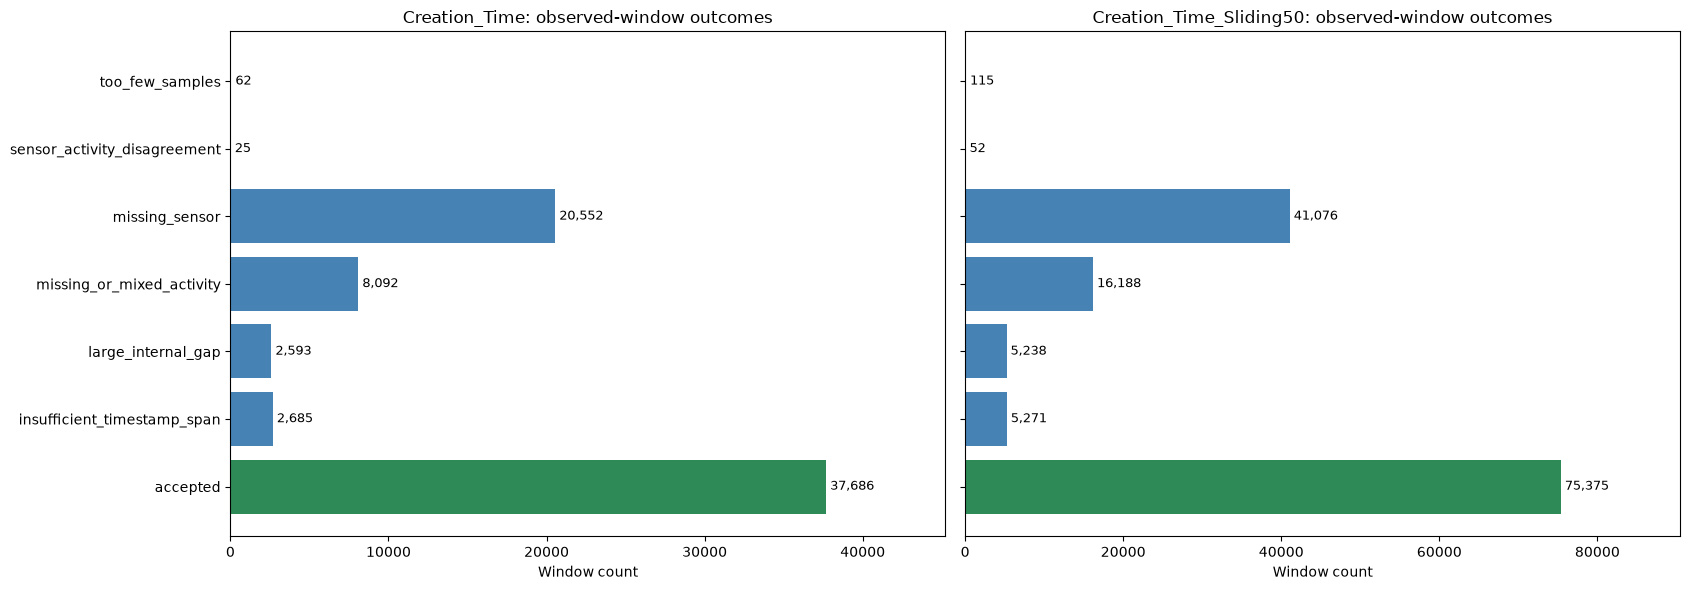

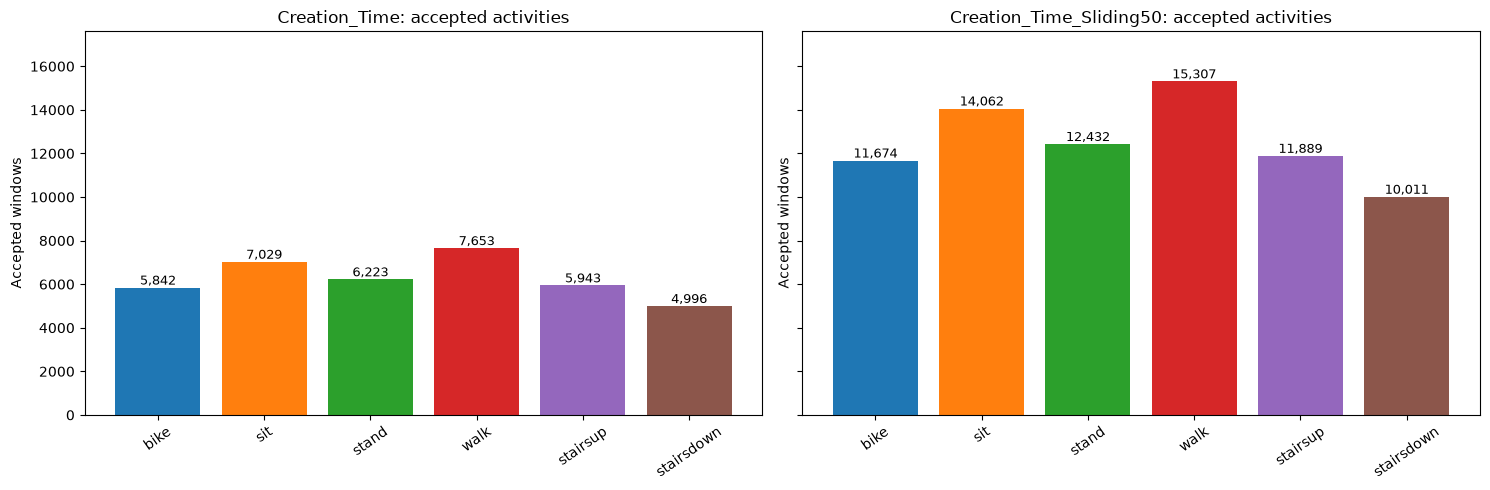

Creation_Time__observed  \
User Model      Device                                  
a    gear       gear_1                            225   
                gear_2                             86   
     lgwatch    lgwatch_1                         943   
                lgwatch_2                         264   
     nexus4     nexus4_1                          877   
...                                               ...   
i    s3         s3_2                              976   
     s3mini     s3mini_1                          941   
                s3mini_2                           85   
     samsungold samsungold_1                     1098   
                samsungold_2                     1097   

                              Creation_Time__accepted  \
User Model      Device                                  
a    gear       gear_1                             88   
                gear_2                             21   
     lgwatch    lgwatch_1                         821   
                lgwatch_2                          25   
     nexus4     nexus4_1                          683   
...                                               ...   
i    s3         s3_2                              757   
     s3mini     s3mini_1                          727   
                s3mini_2                           31   
     samsungold samsungold_1                        0   
                samsungold_2                        0   

                              Creation_Time__accepted_pct  \
User Model      Device                                      
a    gear       gear_1                              39.11   
                gear_2                              24.42   
     lgwatch    lgwatch_1                           87.06   
                lgwatch_2                            9.47   
     nexus4     nexus4_1                            77.88   
...                                                   ...   
i    s3         s3_2                                77.56   
     s3mini     s3mini_1                            77.26   
                s3mini_2                            36.47   
     samsungold samsungold_1                         0.00   
                samsungold_2                         0.00   

                              Creation_Time_Sliding50__observed  \
User Model      Device                                            
a    gear       gear_1                                      447   
                gear_2                                      175   
     lgwatch    lgwatch_1                                  1886   
                lgwatch_2                                   530   
     nexus4     nexus4_1                                   1759   
...                                                         ...   
i    s3         s3_2                                       1952   
     s3mini     s3mini_1                                   1881   
                s3mini_2                                    170   
     samsungold samsungold_1                               2196   
                samsungold_2                               2195   

                              Creation_Time_Sliding50__accepted  \
User Model      Device                                            
a    gear       gear_1                                      178   
                gear_2                                       44   
     lgwatch    lgwatch_1                                  1642   
                lgwatch_2                                    52   
     nexus4     nexus4_1                                   1360   
...                                                         ...   
i    s3         s3_2                                       1505   
     s3mini     s3mini_1                                   1460   
                s3mini_2                                     62   
     samsungold samsungold_1                                  0   
                samsungold_2                                  0   

        

In [2]:
statuses = sorted(set().union(*(set(r['audit']['status'].dropna()) for r in RUNS.values())))
fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
for ax, (clock, r) in zip(axes, RUNS.items()):
    counts = r['audit']['status'].value_counts().reindex(statuses, fill_value=0)
    ax.barh(statuses, counts, color=['seagreen' if s == 'accepted' else 'steelblue' for s in statuses])
    for i, n in enumerate(counts):
        ax.text(n, i, f' {n:,}', va='center', fontsize=9)
    ax.set(title=clock + ': observed-window outcomes', xlabel='Window count')
    ax.margins(x=.2)
fig.tight_layout(); save_plot(fig, 'status_comparison'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (clock, r) in zip(axes, RUNS.items()):
    counts = r['features']['gt'].value_counts().reindex(ACTIVITIES, fill_value=0)
    ax.bar(ACTIVITIES, counts, color=[COLORS[a] for a in ACTIVITIES])
    for i, n in enumerate(counts):
        ax.text(i, n, f'{n:,}', ha='center', va='bottom', fontsize=9)
    ax.set(title=clock + ': accepted activities', ylabel='Accepted windows')
    ax.tick_params(axis='x', rotation=35)
    ax.margins(y=.15)
fig.tight_layout(); save_plot(fig, 'activity_comparison'); plt.show()

retention = []
for clock, r in RUNS.items():
    table = r['audit'].assign(accepted=r['audit']['status'].eq('accepted')).groupby(GROUP, observed=True).agg(
        observed=('status', 'size'), accepted=('accepted', 'sum'))
    table['accepted_pct'] = 100 * table['accepted'] / table['observed']
    retention.append(table.add_prefix(clock + '__'))
retention = pd.concat(retention, axis=1)
display(retention.round(2))

## 2. Choose a participant/device
Run the next cell to see available groups, then edit `USER`, `MODEL`, and `DEVICE`. Optional `VIEW_SECONDS` crops each folder's independently relative timeline; it does not select physically matched data.

In [3]:
available = pd.concat([r['audit'][GROUP] for r in RUNS.values()]).drop_duplicates().sort_values(GROUP)
display(available.reset_index(drop=True))

USER = 'a'
MODEL = 'lgwatch'
DEVICE = 'lgwatch_1'
VIEW_SECONDS = None  # Example: (0, 120)

SELECTED = {}
for clock, r in RUNS.items():
    a = r['audit']
    mask = a['User'].eq(USER) & a['Model'].eq(MODEL) & a['Device'].eq(DEVICE)
    a = a.loc[mask].sort_values('window_id').copy()
    if a.empty:
        print(f'{clock}: no observed windows for this group')
        SELECTED[clock] = a
        continue
    origin = int(a['window_id'].min())
    a['relative_seconds'] = (a['window_id'] - origin).astype(float) * r['config']['window_seconds']
    print(f'{clock}: relative zero is window_id {origin}; {len(a):,} observed windows')
    if VIEW_SECONDS is not None:
        a = a.loc[a['relative_seconds'].between(*VIEW_SECONDS)]
    SELECTED[clock] = a

def sensor_activity(a, sensor):
    count = pd.to_numeric(a[f'{sensor}_label_count'], errors='coerce')
    full = a[f'{sensor}_labeled_n'].eq(a[f'{sensor}_n'])
    labels = a[f'{sensor}_label'].astype('string').str.strip().str.lower()
    return labels.where(count.eq(1) & full & labels.isin(ACTIVITIES), 'missing/mixed').fillna('missing/mixed')

,User,Model,Device
0,a,gear,gear_1
1,a,gear,gear_2
2,a,lgwatch,lgwatch_1
3,a,lgwatch,lgwatch_2
4,a,nexus4,nexus4_1
...,...,...,...
102,i,s3,s3_2
103,i,s3mini,s3mini_1
104,i,s3mini,s3mini_2
105,i,samsungold,samsungold_1


Creation_Time: relative zero is window_id 103908; 943 observed windows
Creation_Time_Sliding50: relative zero is window_id 207816; 1,886 observed windows


## 3. Labeled window timelines and quality diagnostics
Each activity segment spans the nominal window, **not** proof of continuous measurements throughout it. Separate sample-count, span and gap panels show the coverage evidence. Gray segments indicate missing, mixed or unexpected labels; no segment means that sensor has no rows in the observed window. The status strip uses green for accepted and red for rejected. All windows, including rejected ones, appear in these diagnostics.

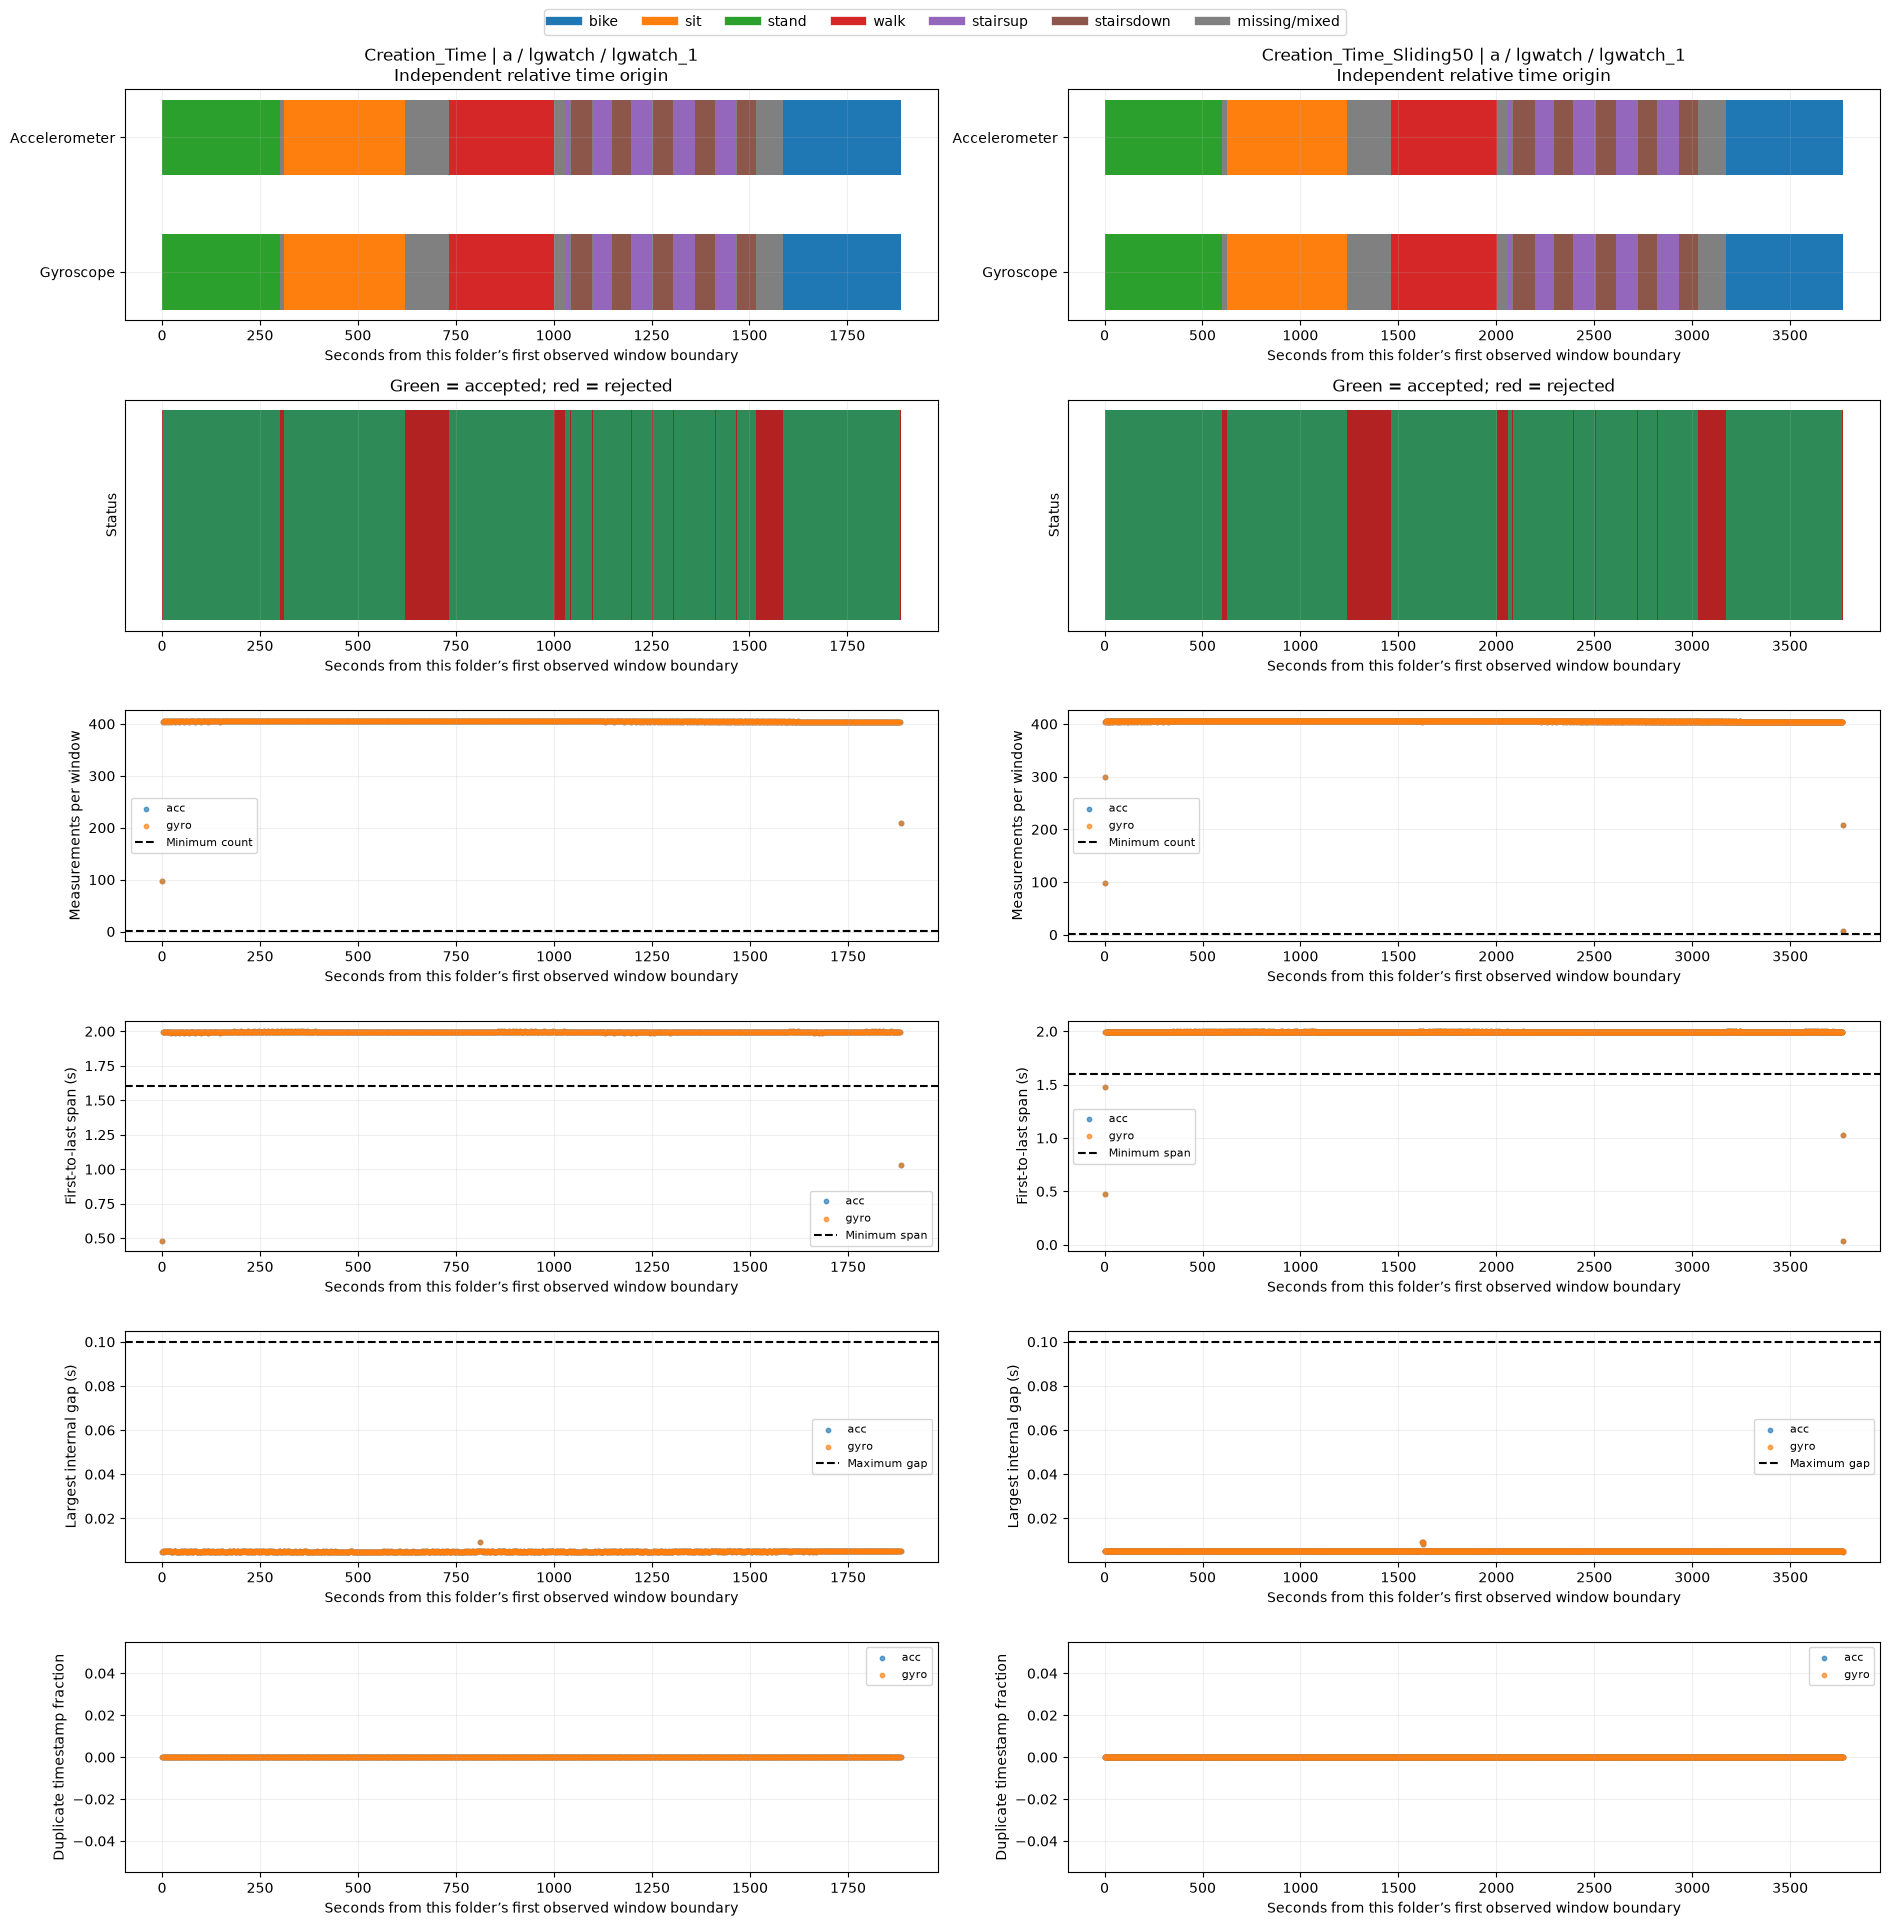

In [4]:
fig, axes = plt.subplots(6, 2, figsize=(19, 19), squeeze=False)
for col, (clock, a) in enumerate(SELECTED.items()):
    r = RUNS[clock]; cfg = r['config']; w = cfg['window_seconds']
    if a.empty:
        for ax in axes[:, col]:
            ax.text(.5, .5, 'No windows in selection', transform=ax.transAxes, ha='center')
        continue
    t = a['relative_seconds'].to_numpy(dtype=float)
    for sensor, y in [('acc', 1), ('gyro', 0)]:
        labels = sensor_activity(a, sensor)
        present = a[f'{sensor}_n'].notna()
        for label in ACTIVITIES + ['missing/mixed']:
            indices = np.flatnonzero((labels.eq(label) & present).to_numpy(dtype=bool))
            if len(indices):
                axes[0, col].broken_barh([(t[i], w) for i in indices], (y-.28, .56),
                                         facecolors=COLORS[label], edgecolors='none')
    axes[0, col].set(yticks=[0, 1], yticklabels=['Gyroscope', 'Accelerometer'],
                     title=f'{clock} | {USER} / {MODEL} / {DEVICE}\nIndependent relative time origin')
    for accepted, color in [(True, 'seagreen'), (False, 'firebrick')]:
        ids = np.flatnonzero(a['status'].eq('accepted').eq(accepted).to_numpy())
        axes[1, col].broken_barh([(t[i], w) for i in ids], (0, 1), facecolors=color)
    axes[1, col].set(yticks=[], ylabel='Status', title='Green = accepted; red = rejected')
    for sensor, color in [('acc', 'tab:blue'), ('gyro', 'tab:orange')]:
        for row, field in [(2, 'n'), (3, 'span_seconds'), (4, 'max_gap_seconds'),
                           (5, 'duplicate_timestamp_fraction')]:
            values = pd.to_numeric(a[f'{sensor}_{field}'], errors='coerce').to_numpy(dtype=float, na_value=np.nan)
            axes[row, col].scatter(t, values, s=10, alpha=.65, color=color, label=sensor)
    axes[2, col].axhline(cfg['minimum_samples_per_sensor'], color='black', ls='--', label='Minimum count')
    axes[3, col].axhline(w * cfg['minimum_time_span_ratio'], color='black', ls='--', label='Minimum span')
    if cfg['maximum_internal_gap_seconds'] is not None:
        axes[4, col].axhline(cfg['maximum_internal_gap_seconds'], color='black', ls='--', label='Maximum gap')
    for row, ylabel in [(2, 'Measurements per window'), (3, 'First-to-last span (s)'),
                         (4, 'Largest internal gap (s)'), (5, 'Duplicate timestamp fraction')]:
        axes[row, col].set_ylabel(ylabel)
        axes[row, col].legend(fontsize=8, loc='best')
    for ax in axes[:, col]:
        ax.set_xlabel('Seconds from this folder’s first observed window boundary')
        ax.grid(alpha=.2)
        if VIEW_SECONDS is not None:
            ax.set_xlim(*VIEW_SECONDS)
handles = [Line2D([0], [0], color=COLORS[a], lw=6, label=a) for a in ACTIVITIES + ['missing/mixed']]
fig.legend(handles=handles, loc='upper center', ncol=7, bbox_to_anchor=(.5, 1.015))
fig.tight_layout(); save_plot(fig, f'timeline_{USER}_{MODEL}_{DEVICE}'); plt.show()

## 4. Audit details and low-count windows
These tables make the graph labels inspectable. A window may fail several rules; `status` reports only the first failure. Integer timestamps are loaded as nullable integers to avoid loss of precision in large creation timestamps.

In [5]:
flags = ['both_sensors', 'labels_valid', 'labels_agree', 'axis_values_valid',
         'enough_samples', 'enough_time_span', 'internal_gaps_ok', 'finite_features']
fields = ['n', 'first_time', 'last_time', 'label', 'span_seconds', 'max_gap_seconds']
for clock, a in SELECTED.items():
    print('\n' + clock)
    if a.empty:
        continue
    display(a['status'].value_counts().rename('windows').to_frame())
    for flag in flags:
        if flag in a:
            print(f'{flag}: {(a[flag].astype("string").str.lower() == "false").sum():,} failed')
    cols = GROUP + ['window_id', 'relative_seconds', 'status'] + [f'{s}_{v}' for s in ['acc', 'gyro'] for v in fields]
    display(a[cols].head(30))

for clock, r in RUNS.items():
    a = r['audit']
    low = a.loc[a['acc_n'].between(1, 10)].copy()
    print(f'\n{clock}: {len(low):,} windows with 1–10 accelerometer rows; '
          f'{low["status"].eq("accepted").sum():,} accepted')
    display(low['status'].value_counts().rename('windows').to_frame())
    display(low[GROUP + ['window_id', 'status', 'acc_n', 'gyro_n', 'acc_span_seconds',
                         'acc_max_gap_seconds', 'enough_samples', 'enough_time_span',
                         'internal_gaps_ok']].head(30))


Creation_Time


,windows
status,
accepted,821
missing_or_mixed_activity,120
insufficient_timestamp_span,2


both_sensors: 0 failed
labels_valid: 120 failed
labels_agree: 103 failed
axis_values_valid: 0 failed
enough_samples: 0 failed
enough_time_span: 2 failed
internal_gaps_ok: 0 failed
finite_features: 0 failed


,User,Model,Device,window_id,relative_seconds,status,acc_n,acc_first_time,acc_last_time,acc_label,acc_span_seconds,acc_max_gap_seconds,gyro_n,gyro_first_time,gyro_last_time,gyro_label,gyro_span_seconds,gyro_max_gap_seconds
311,a,lgwatch,lgwatch_1,103908,0.0,insufficient_timestamp_span,98,207817520343346,207817999682946,stand,0.479340,0.005005,98,207817520343346,207817999682946,stand,0.479340,0.005005
312,a,lgwatch,lgwatch_1,103909,2.0,accepted,404,207818004626794,207819996295495,stand,1.991669,0.005035,404,207818004626794,207819996295495,stand,1.991669,0.005035
313,a,lgwatch,lgwatch_1,103910,4.0,accepted,405,207820001208825,207821997940950,stand,1.996732,0.005035,405,207820001208825,207821997940950,stand,1.996732,0.005035
314,a,lgwatch,lgwatch_1,103911,6.0,accepted,405,207822002884798,207823999405794,stand,1.996521,0.005005,405,207822002884798,207823999405794,stand,1.996521,0.005005
315,a,lgwatch,lgwatch_1,103912,8.0,accepted,404,207824004441194,207825996018343,stand,1.991577,0.005035,404,207824004441194,207825996018343,stand,1.991577,0.005035
316,a,lgwatch,lgwatch_1,103913,10.0,accepted,405,207826000962190,207827997483186,stand,1.996521,0.005035,405,207826000962190,207827997483186,stand,1.996521,0.005035
317,a,lgwatch,lgwatch_1,103914,12.0,accepted,405,207828002427034,207829998948030,stand,1.996521,0.005035,405,207828002427034,207829998948030,stand,1.996521,0.005035
318,a,lgwatch,lgwatch_1,103915,14.0,accepted,404,207830003891878,207831995451142,stand,1.991559,0.005035,404,207830003891878,207831995451142,stand,1.991559,0.005035
319,a,lgwatch,lgwatch_1,103916,16.0,accepted,405,207832000394989,207833996702362,stand,1.996307,0.005035,405,207832000394989,207833996702362,stand,1.996307,0.005035
320,a,lgwatch,lgwatch_1,103917,18.0,accepted,405,207834001676728,207835998075653,stand,1.996399,0.005035,405,207834001676728,207835998075653,stand,1.996399,0.005035



Creation_Time_Sliding50


,windows
status,
accepted,1642
missing_or_mixed_activity,240
insufficient_timestamp_span,4


... (4 outputs left out)

,User,Model,Device,window_id,status,acc_n,gyro_n,acc_span_seconds,acc_max_gap_seconds,enough_samples,enough_time_span,internal_gaps_ok
10,a,gear,gear_1,13970,insufficient_timestamp_span,9,8,0.130381,0.070471,True,False,True
13,a,gear,gear_1,13973,missing_sensor,1,<NA>,0.000000,NaN,False,False,False
46,a,gear,gear_1,14006,insufficient_timestamp_span,8,7,0.056585,0.013532,True,False,True
200,a,gear,gear_1,14161,insufficient_timestamp_span,10,10,0.089509,0.010173,True,False,True
224,a,gear,gear_1,14185,insufficient_timestamp_span,10,10,0.089737,0.010100,True,False,True
1518,a,nexus4,nexus4_1,712282849,insufficient_timestamp_span,10,10,0.045288,0.005066,True,False,True
1663,a,nexus4,nexus4_1,712348465,insufficient_timestamp_span,9,8,0.040283,0.005096,True,False,True
1850,a,nexus4,nexus4_1,712348656,missing_or_mixed_activity,2,2,0.004846,0.004846,True,False,True
2076,a,nexus4,nexus4_1,712348895,too_few_samples,1,1,0.000000,NaN,False,False,False
2231,a,nexus4,nexus4_1,712349055,insufficient_timestamp_span,6,6,0.076283,0.055378,True,False,True



Creation_Time_Sliding50: 523 windows with 1–10 accelerometer rows; 0 accepted


,windows
status,
insufficient_timestamp_span,266
too_few_samples,114
missing_or_mixed_activity,91
missing_sensor,49
large_internal_gap,3


,User,Model,Device,window_id,status,acc_n,gyro_n,acc_span_seconds,acc_max_gap_seconds,enough_samples,enough_time_span,internal_gaps_ok
20,a,gear,gear_1,27940,insufficient_timestamp_span,9,8,0.130381,0.070471,True,False,True
26,a,gear,gear_1,27946,missing_sensor,1,<NA>,0.000000,NaN,False,False,False
92,a,gear,gear_1,28012,insufficient_timestamp_span,8,7,0.056585,0.013532,True,False,True
131,a,gear,gear_1,28051,insufficient_timestamp_span,5,4,0.054452,0.022809,True,False,True
151,a,gear,gear_1,28071,missing_or_mixed_activity,1,1,0.000000,NaN,False,False,False
202,a,gear,gear_1,28123,insufficient_timestamp_span,10,10,0.089080,0.010178,True,False,True
398,a,gear,gear_1,28322,insufficient_timestamp_span,10,10,0.089509,0.010173,True,False,True
446,a,gear,gear_1,28370,insufficient_timestamp_span,10,10,0.089737,0.010100,True,False,True
474,a,gear,gear_2,1601,insufficient_timestamp_span,3,2,0.019896,0.010034,True,False,True
503,a,gear,gear_2,1645,missing_sensor,1,<NA>,0.000000,NaN,False,False,False


## 5. Why 1–10 measurements cannot pass the supplied settings
With a two-second window, the required first-to-last span is 1.6 seconds. For n sorted timestamps, there are n−1 adjacent gaps. If every gap is at most 0.1 seconds, their total span is at most (n−1) × 0.1 seconds. Thus at least 17 measurements are mathematically necessary to meet both rules. This is only a necessary lower bound, not a guarantee of acceptance or an estimate of typical sampling rate. Duplicate timestamps cannot improve this bound.

One row fails the explicit minimum count of 2. Two to ten rows can pass that count test, but cannot pass both the span and gap tests. Earlier failures (such as mixed labels) may mask the later failing rule in the status column. Changing or disabling thresholds changes this conclusion.

In [6]:
for clock, r in RUNS.items():
    cfg = r['config']
    span = cfg['window_seconds'] * cfg['minimum_time_span_ratio']
    gap = cfg['maximum_internal_gap_seconds']
    if gap is not None and gap > 0:
        lower = int(np.ceil(np.nextafter(span / gap, -np.inf))) + 1
        print(f'{clock}: minimum span {span:g}s, maximum gap {gap:g}s; '
              f'necessary sample count >= {max(lower, cfg["minimum_samples_per_sensor"])} per sensor')
    else:
        print(f'{clock}: no positive maximum-gap constraint; the 17-row bound does not apply.')

Creation_Time: minimum span 1.6s, maximum gap 0.1s; necessary sample count >= 17 per sensor
Creation_Time_Sliding50: minimum span 1.6s, maximum gap 0.1s; necessary sample count >= 17 per sensor


# Inspect sequences and gaps

History length: up to 5 accepted windows.
Activity changes do NOT break a run.
Missing/rejected window positions DO break a run.


,Creation_Time,Creation_Time_Sliding50
accepted_windows,37686.00,75375.00
consecutive_runs,3809.00,4064.00
mean_run_length,9.89,18.55
median_run_length,3.00,6.00
maximum_run_length,192.00,384.00
breaks_between_accepted_runs,3727.00,3982.00
unavailable_positions_between_runs,17817.00,35840.00
full_5_window_examples,27177.00,61773.00
targets_lost_if_full_history_required,10509.00,13602.00
targets_needing_padding_if_all_kept,10509.00,13602.00


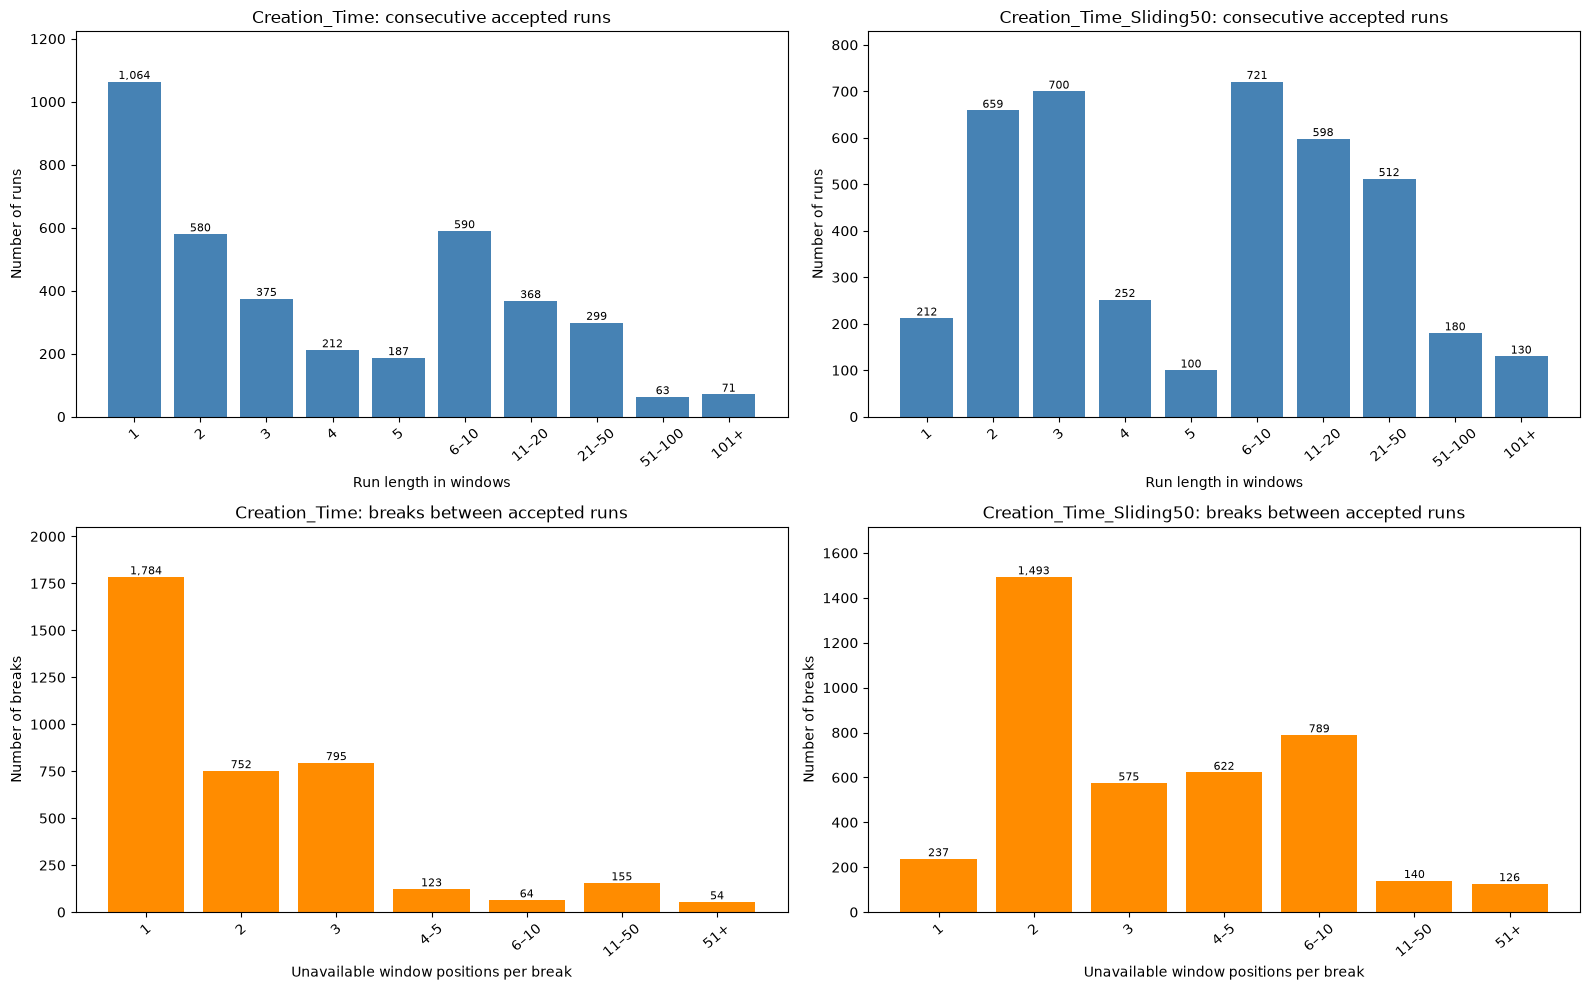


Creation_Time

Run lengths and padding needs by participant/device:


,User,Model,Device,observed_windows,accepted_windows,rejected_observed_windows,runs,mean_run_length,median_run_length,min_run_length,max_run_length,full_history_examples,short_history_targets,padding_slots,breaks_between_accepted_runs,unavailable_positions_between_runs,full_history_retained_pct,targets_needing_padding_pct,padding_slots_pct
0,a,gear,gear_1,225,88,137,63,1.4,1.0,1,8,4,84,301,62,136,4.55,95.45,68.41
1,a,gear,gear_2,86,21,65,3,7.0,4.0,4,13,9,12,30,2,45,42.86,57.14,28.57
2,a,lgwatch,lgwatch_1,943,821,122,14,58.64,26.0,6,154,765,56,140,13,120,93.18,6.82,3.41
3,a,lgwatch,lgwatch_2,264,25,239,7,3.57,3.0,1,6,4,21,59,6,758,16.00,84.00,47.20
4,a,nexus4,nexus4_1,877,683,194,65,10.51,4.0,1,111,496,187,519,64,255,72.62,27.38,15.20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,i,s3,s3_2,976,757,219,63,12.02,4.0,1,147,575,182,507,62,216,75.96,24.04,13.39
103,i,s3mini,s3mini_1,941,727,214,74,9.82,3.0,1,155,513,214,604,73,213,70.56,29.44,16.62
104,i,s3mini,s3mini_2,85,31,54,2,15.5,15.5,1,30,26,5,14,1,45,83.87,16.13,9.03
105,i,samsungold,samsungold_1,1098,0,1098,0,<NA>,<NA>,<NA>,<NA>,0,0,0,0,0,NaN,NaN,NaN



Exact run-length distribution:


,run_length,number_of_runs,accepted_windows,full_history_examples,padding_slots
0,1,1064,1064,0,4256
1,2,580,1160,0,4060
2,3,375,1125,0,3375
3,4,212,848,0,2120
4,5,187,935,187,1870
...,...,...,...,...,...
115,161,2,322,314,20
116,163,1,163,159,10
117,172,1,172,168,10
118,184,1,184,180,10



Largest breaks between accepted runs:


,User,Model,Device,previous_accepted_id,next_accepted_id,id_difference,unavailable_window_positions,accepted_start_separation_seconds
0,f,lgwatch,lgwatch_2,103424,104079,655,654,1310.0
1,d,lgwatch,lgwatch_2,104783,105211,428,427,856.0
2,a,lgwatch,lgwatch_2,61906,62325,419,418,838.0
3,g,lgwatch,lgwatch_2,57551,57917,366,365,732.0
4,a,lgwatch,lgwatch_2,62351,62667,316,315,632.0
5,e,lgwatch,lgwatch_2,107789,108098,309,308,618.0
6,e,lgwatch,lgwatch_2,107501,107775,274,273,548.0
7,c,lgwatch,lgwatch_2,61001,61257,256,255,512.0
8,g,lgwatch,lgwatch_2,57337,57547,210,209,420.0
9,e,nexus4,nexus4_1,712394395,712394562,167,166,334.0


... (2 outputs left out)


Exact run-length distribution:


,run_length,number_of_runs,accepted_windows,full_history_examples,padding_slots
0,1,212,212,0,848
1,2,659,1318,0,4613
2,3,700,2100,0,6300
3,4,252,1008,0,2520
4,5,100,500,100,1000
...,...,...,...,...,...
180,322,2,644,636,20
181,327,1,327,323,10
182,344,1,344,340,10
183,368,1,368,364,10



Largest breaks between accepted runs:


,User,Model,Device,previous_accepted_id,next_accepted_id,id_difference,unavailable_window_positions,accepted_start_separation_seconds
0,f,lgwatch,lgwatch_2,206848,208157,1309,1308,1309.0
1,d,lgwatch,lgwatch_2,209567,210422,855,854,855.0
2,a,lgwatch,lgwatch_2,123861,124650,789,788,789.0
3,g,lgwatch,lgwatch_2,115102,115834,732,731,732.0
4,a,lgwatch,lgwatch_2,124702,125333,631,630,631.0
5,e,lgwatch,lgwatch_2,215579,216195,616,615,616.0
6,e,lgwatch,lgwatch_2,215002,215550,548,547,548.0
7,c,lgwatch,lgwatch_2,122002,122514,512,511,512.0
8,g,lgwatch,lgwatch_2,114675,115093,418,417,418.0
9,e,nexus4,nexus4_1,1424788791,1424789124,333,332,333.0


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HISTORY_LENGTH = 5
GROUP_KEYS = ["User", "Model", "Device"]

if not isinstance(HISTORY_LENGTH, int) or HISTORY_LENGTH < 1:
    raise ValueError("HISTORY_LENGTH must be a positive integer.")

SEQUENCE_REPORTS = {}


def analyze_runs(clock, run):
    cfg = run["config"]
    audit = run["audit"].copy()

    # Window IDs increase by 1 for consecutive windows in both versions:
    # original non-overlapping code and the proposed overlapping code.
    overlap = float(cfg.get("overlap_fraction", 0))
    step_seconds = float(
        cfg.get(
            "step_seconds",
            cfg["window_seconds"] * (1 - overlap),
        )
    )
    window_seconds = float(cfg["window_seconds"])

    if step_seconds <= 0:
        raise ValueError(f"{clock}: invalid step duration.")

    keys = GROUP_KEYS + ["window_id"]

    if audit[keys].isna().any().any():
        raise ValueError(f"{clock}: missing group identifiers or window IDs.")

    if audit.duplicated(keys).any():
        raise ValueError(f"{clock}: duplicate window keys.")

    audit = audit.sort_values(keys).reset_index(drop=True)

    accepted = audit.loc[
        audit["status"].eq("accepted")
    ].copy()

    # Preserve groups with zero accepted windows in the group report.
    group_report = (
        audit.groupby(GROUP_KEYS, observed=True)
        .agg(
            observed_windows=("window_id", "size"),
            accepted_windows=(
                "status",
                lambda s: s.eq("accepted").sum(),
            ),
        )
    )

    group_report["rejected_observed_windows"] = (
        group_report["observed_windows"]
        - group_report["accepted_windows"]
    )

    empty_run_columns = GROUP_KEYS + [
        "run_id",
        "start_window_id",
        "end_window_id",
        "run_length",
        "temporal_extent_seconds",
        "full_history_examples",
        "short_history_targets",
        "padding_slots",
    ]

    if accepted.empty:
        runs = pd.DataFrame(columns=empty_run_columns)
        gaps = pd.DataFrame()
    else:
        grouped = accepted.groupby(
            GROUP_KEYS, observed=True, sort=False
        )

        accepted["previous_accepted_id"] = (
            grouped["window_id"].shift()
        )

        # Subtract integer window IDs before any float conversion.
        accepted["id_difference"] = (
            accepted["window_id"]
            - accepted["previous_accepted_id"]
        )

        accepted["new_run"] = (
            accepted["previous_accepted_id"].isna()
            | accepted["id_difference"].ne(1)
        ).fillna(True)

        accepted["run_id"] = (
            accepted.groupby(
                GROUP_KEYS, observed=True, sort=False
            )["new_run"]
            .cumsum()
            .astype("int64")
        )

        runs = (
            accepted.groupby(
                GROUP_KEYS + ["run_id"],
                observed=True,
                sort=False,
            )
            .agg(
                start_window_id=("window_id", "min"),
                end_window_id=("window_id", "max"),
                run_length=("window_id", "size"),
            )
            .reset_index()
        )

        runs["temporal_extent_seconds"] = (
            window_seconds
            + (runs["run_length"] - 1) * step_seconds
        )

        # Full-history policy:
        # only predict when HISTORY_LENGTH real windows are available.
        runs["full_history_examples"] = (
            runs["run_length"] - HISTORY_LENGTH + 1
        ).clip(lower=0)

        # Variable-history policy:
        # predict every accepted window, using up to H windows of history.
        # The initial targets in each run need padding.
        runs["short_history_targets"] = np.minimum(
            runs["run_length"], HISTORY_LENGTH - 1
        )

        m = runs["short_history_targets"]

        # Sum of missing positions for prefixes of lengths 1, 2, ..., m:
        # (H-1) + (H-2) + ... + (H-m).
        runs["padding_slots"] = (
            m * HISTORY_LENGTH - m * (m + 1) // 2
        ).astype("int64")

        # One row for each break between accepted runs.
        gap_mask = (
            accepted["previous_accepted_id"].notna()
            & accepted["id_difference"].gt(1)
        ).fillna(False)

        gaps = accepted.loc[
            gap_mask,
            GROUP_KEYS
            + [
                "previous_accepted_id",
                "window_id",
                "id_difference",
            ],
        ].copy()

        gaps = gaps.rename(
            columns={
                "window_id": "next_accepted_id",
            }
        )

        gaps["unavailable_window_positions"] = (
            gaps["id_difference"] - 1
        ).astype("int64")

        # Distance between the starts of the accepted windows.
        # Not necessarily an interval with no raw measurements.
        gaps["accepted_start_separation_seconds"] = (
            gaps["id_difference"].astype(float)
            * step_seconds
        )

    if not runs.empty:
        run_stats = (
            runs.groupby(GROUP_KEYS, observed=True)
            .agg(
                runs=("run_length", "size"),
                mean_run_length=("run_length", "mean"),
                median_run_length=("run_length", "median"),
                min_run_length=("run_length", "min"),
                max_run_length=("run_length", "max"),
                full_history_examples=(
                    "full_history_examples", "sum"
                ),
                short_history_targets=(
                    "short_history_targets", "sum"
                ),
                padding_slots=("padding_slots", "sum"),
            )
        )

        group_report = group_report.join(run_stats)
    else:
        for col in [
            "runs",
            "mean_run_length",
            "median_run_length",
            "min_run_length",
            "max_run_length",
            "full_history_examples",
            "short_history_targets",
            "padding_slots",
        ]:
            group_report[col] = np.nan

    count_columns = [
        "runs",
        "full_history_examples",
        "short_history_targets",
        "padding_slots",
    ]

    for col in count_columns:
        group_report[col] = (
            group_report[col].fillna(0).astype("int64")
        )

    # Within each group, the number of breaks between accepted runs.
    group_report["breaks_between_accepted_runs"] = (
        group_report["runs"] - 1
    ).clip(lower=0)

    if not gaps.empty:
        gap_counts = (
            gaps.groupby(GROUP_KEYS, observed=True)[
                "unavailable_window_positions"
            ]
            .sum()
            .rename("unavailable_positions_between_runs")
        )
        group_report = group_report.join(gap_counts)
    else:
        group_report[
            "unavailable_positions_between_runs"
        ] = 0

    group_report["unavailable_positions_between_runs"] = (
        group_report["unavailable_positions_between_runs"]
        .fillna(0)
        .astype("int64")
    )

    denominator = group_report["accepted_windows"].replace(
        0, np.nan
    )

    group_report["full_history_retained_pct"] = (
        100
        * group_report["full_history_examples"]
        / denominator
    )

    group_report["targets_needing_padding_pct"] = (
        100
        * group_report["short_history_targets"]
        / denominator
    )

    group_report["padding_slots_pct"] = (
        100
        * group_report["padding_slots"]
        / (denominator * HISTORY_LENGTH)
    )

    if runs.empty:
        distribution = pd.DataFrame(
            columns=[
                "run_length",
                "number_of_runs",
                "accepted_windows",
                "full_history_examples",
                "padding_slots",
            ]
        )
    else:
        distribution = (
            runs.groupby("run_length", observed=True)
            .agg(
                number_of_runs=("run_id", "size"),
                accepted_windows=("run_length", "sum"),
                full_history_examples=(
                    "full_history_examples", "sum"
                ),
                padding_slots=("padding_slots", "sum"),
            )
            .reset_index()
        )

    n_accepted = len(accepted)
    n_full = int(runs["full_history_examples"].sum())
    n_short = int(runs["short_history_targets"].sum())
    n_padding = int(runs["padding_slots"].sum())

    summary = {
        "accepted_windows": n_accepted,
        "consecutive_runs": len(runs),
        "mean_run_length": (
            runs["run_length"].mean()
            if len(runs) else np.nan
        ),
        "median_run_length": (
            runs["run_length"].median()
            if len(runs) else np.nan
        ),
        "maximum_run_length": (
            runs["run_length"].max()
            if len(runs) else np.nan
        ),
        "breaks_between_accepted_runs": (
            group_report["breaks_between_accepted_runs"].sum()
        ),
        "unavailable_positions_between_runs": (
            group_report[
                "unavailable_positions_between_runs"
            ].sum()
        ),
        f"full_{HISTORY_LENGTH}_window_examples": n_full,
        "targets_lost_if_full_history_required": n_short,
        "targets_needing_padding_if_all_kept": n_short,
        "targets_needing_padding_pct": (
            100 * n_short / n_accepted
            if n_accepted else np.nan
        ),
        "padding_slots_pct": (
            100 * n_padding
            / (n_accepted * HISTORY_LENGTH)
            if n_accepted else np.nan
        ),
        "window_seconds": window_seconds,
        "step_seconds": step_seconds,
    }

    return {
        "summary": summary,
        "by_group": group_report.reset_index(),
        "length_distribution": distribution,
        "runs": runs,
        "gaps": gaps,
    }


for clock, run in RUNS.items():
    SEQUENCE_REPORTS[clock] = analyze_runs(clock, run)


print(
    f"History length: up to {HISTORY_LENGTH} accepted windows.\n"
    "Activity changes do NOT break a run.\n"
    "Missing/rejected window positions DO break a run."
)

summary_table = pd.DataFrame(
    {
        clock: report["summary"]
        for clock, report in SEQUENCE_REPORTS.items()
    }
)

display(summary_table.round(2))


# ------------------------------------------------------------
# Graphs: exact short lengths, grouped longer lengths, gap sizes
# ------------------------------------------------------------

n_clocks = len(SEQUENCE_REPORTS)

fig, axes = plt.subplots(
    2,
    n_clocks,
    figsize=(8 * n_clocks, 10),
    squeeze=False,
)

length_edges = [0, 1, 2, 3, 4, 5, 10, 20, 50, 100, np.inf]
length_labels = [
    "1", "2", "3", "4", "5",
    "6–10", "11–20", "21–50", "51–100", "101+",
]

gap_edges = [0, 1, 2, 3, 5, 10, 50, np.inf]
gap_labels = ["1", "2", "3", "4–5", "6–10", "11–50", "51+"]

for col, (clock, report) in enumerate(
    SEQUENCE_REPORTS.items()
):
    runs = report["runs"]
    gaps = report["gaps"]

    ax = axes[0, col]

    if runs.empty:
        ax.text(
            0.5, 0.5, "No accepted runs",
            transform=ax.transAxes,
            ha="center",
        )
    else:
        bins = pd.cut(
            runs["run_length"],
            bins=length_edges,
            labels=length_labels,
            include_lowest=True,
        )

        counts = bins.value_counts(sort=False)

        ax.bar(
            length_labels,
            counts.to_numpy(),
            color="steelblue",
        )

        for i, count in enumerate(counts):
            ax.text(
                i, count, f"{count:,}",
                ha="center", va="bottom", fontsize=8,
            )

    ax.set(
        title=f"{clock}: consecutive accepted runs",
        xlabel="Run length in windows",
        ylabel="Number of runs",
    )
    ax.tick_params(axis="x", rotation=40)
    ax.margins(y=0.15)

    ax = axes[1, col]

    if gaps.empty:
        ax.text(
            0.5, 0.5, "No breaks between accepted runs",
            transform=ax.transAxes,
            ha="center",
        )
    else:
        bins = pd.cut(
            gaps["unavailable_window_positions"],
            bins=gap_edges,
            labels=gap_labels,
            include_lowest=True,
        )

        counts = bins.value_counts(sort=False)

        ax.bar(
            gap_labels,
            counts.to_numpy(),
            color="darkorange",
        )

        for i, count in enumerate(counts):
            ax.text(
                i, count, f"{count:,}",
                ha="center", va="bottom", fontsize=8,
            )

    ax.set(
        title=f"{clock}: breaks between accepted runs",
        xlabel="Unavailable window positions per break",
        ylabel="Number of breaks",
    )
    ax.tick_params(axis="x", rotation=40)
    ax.margins(y=0.15)

fig.tight_layout()
plt.show()


# ------------------------------------------------------------
# Tables
# ------------------------------------------------------------

for clock, report in SEQUENCE_REPORTS.items():
    print(f"\n{'=' * 72}\n{clock}")

    print("\nRun lengths and padding needs by participant/device:")
    display(
        report["by_group"]
        .sort_values(GROUP_KEYS)
        .round(2)
        .reset_index(drop=True)
    )

    print("\nExact run-length distribution:")
    display(report["length_distribution"])

    print("\nLargest breaks between accepted runs:")
    gaps = report["gaps"]

    if gaps.empty:
        print("None.")
    else:
        display(
            gaps.sort_values(
                "unavailable_window_positions",
                ascending=False,
            )
            .head(20)
            .reset_index(drop=True)
        )

In [8]:
# Leave empty to include every audited device model.
# Set to {"samsungold"} to check all other models.
EXCLUDE_MODELS = set({"samsungold"})

for clock, report in SEQUENCE_REPORTS.items():
    groups = report["by_group"].copy()

    groups = groups.loc[
        ~groups["Model"].isin(EXCLUDE_MODELS)
    ].copy()

    groups["has_5_consecutive"] = (
        groups["max_run_length"]
        .fillna(0)
        .ge(5)
    )

    summary = (
        groups.groupby("User", observed=True)
        .agg(
            audited_device_groups=("Device", "size"),
            device_groups_with_5=(
                "has_5_consecutive", "sum"
            ),
            every_device_has_5=(
                "has_5_consecutive", "all"
            ),
        )
        .reset_index()
    )

    print(f"\n{clock}")
    display(summary)

    print("Device groups preventing qualification:")
    display(
        groups.loc[
            ~groups["has_5_consecutive"],
            [
                "User",
                "Model",
                "Device",
                "accepted_windows",
                "max_run_length",
            ],
        ]
        .sort_values(["User", "Model", "Device"])
        .reset_index(drop=True)
    )


Creation_Time


,User,audited_device_groups,device_groups_with_5,every_device_has_5
0,a,10,10,True
1,b,10,8,False
2,c,10,9,False
3,d,10,9,False
4,e,10,9,False
5,f,10,9,False
6,g,10,8,False
7,h,10,8,False
8,i,9,8,False


Device groups preventing qualification:


,User,Model,Device,accepted_windows,max_run_length
0,b,lgwatch,lgwatch_2,0,<NA>
1,b,s3mini,s3mini_2,0,<NA>
2,c,s3mini,s3mini_2,3,2
3,d,s3mini,s3mini_2,0,<NA>
4,e,gear,gear_2,16,4
5,f,s3,s3_1,0,<NA>
6,g,gear,gear_2,3,1
7,g,lgwatch,lgwatch_1,0,<NA>
8,h,gear,gear_2,1,1
9,h,lgwatch,lgwatch_2,0,<NA>



Creation_Time_Sliding50


,User,audited_device_groups,device_groups_with_5,every_device_has_5
0,a,10,10,True
1,b,10,8,False
2,c,10,9,False
3,d,10,9,False
4,e,10,10,True
5,f,10,9,False
6,g,10,8,False
7,h,10,8,False
8,i,9,8,False


Device groups preventing qualification:


,User,Model,Device,accepted_windows,max_run_length
0,b,lgwatch,lgwatch_2,0,<NA>
1,b,s3mini,s3mini_2,0,<NA>
2,c,s3mini,s3mini_2,10,4
3,d,s3mini,s3mini_2,0,<NA>
4,f,s3,s3_1,0,<NA>
5,g,gear,gear_2,6,2
6,g,lgwatch,lgwatch_1,0,<NA>
7,h,gear,gear_2,2,1
8,h,lgwatch,lgwatch_2,0,<NA>
9,i,gear,gear_2,0,<NA>
